# 6주차 실습 — Image Segmentation: 흉부 X-ray 폐·심장 분할
### 비전AI와비즈니스 | 경영대학 AI빅데이터융합경영학과

**5주차와의 연결**
5주차 분류 모델(ConvNeXt)은 테스트 정확도 0.851을 보였지만, Grad-CAM상 판단 근거가 **폐야가 아닌 종격동·척추·이미지 모서리**에 있었다 (shortcut learning 의심).
→ 이번 주에는 **사전학습된 폐·심장 분할 모델**로 폐 영역을 찾아내고, **폐 영역만 잘라 다시 분류**했을 때 성능과 판단 근거가 어떻게 바뀌는지 확인한다.

| 항목 | 내용 |
|---|---|
| 데이터셋 | `hf-vision/chest-xray-pneumonia` (3주차와 동일, 소아 흉부 X-ray AP) |
| 분할 모델 | `ianpan/chest-x-ray-basic` (EfficientNetV2-S + U-Net, 우폐·좌폐·심장) |
| 분류 모델 | `facebook/convnext-tiny-224` (3주차와 동일 설정으로 재학습) |

**구성**
- **Part 1. Segmentation 추론** — 마스크 시각화, CTR(심흉곽비), 정답 마스크 없이 품질 점검
- **Part 2. 활용** — 폐 영역 crop → 분류 재학습 → 5주차와 성능·Grad-CAM 비교


---
## 0. 설정 & 설치
런타임 → 런타임 유형 변경 → **T4 GPU**

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q transformers datasets evaluate accelerate timm albumentations
print("설치 완료")


name, memory.total [MiB]
Tesla T4, 15360 MiB
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.4 MB/s eta 0:00:00
설치 완료


In [2]:
DATASET    = "hf-vision/chest-xray-pneumonia"
SEG_MODEL  = "ianpan/chest-x-ray-basic"
CLS_MODEL  = "facebook/convnext-tiny-224"
SEED = 42
CROP_MODE = "mask"   # "mask": 폐 바깥을 검게 지움 / "bbox": 폐를 포함하는 사각형만 자름

# 5주차 결과 (비교 기준)
WEEK5 = {"accuracy": 0.851, "f1_macro": 0.824, "sensitivity": 0.995, "specificity": 0.611}

import torch, numpy as np, cv2, time
import matplotlib.pyplot as plt
from PIL import Image
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)


device: cuda


---
# Part 1. Segmentation 추론

## 1. 데이터 불러오기


In [3]:
from datasets import load_dataset, ClassLabel, Image as HFImage

raw = load_dataset(DATASET)
LABEL_COL = [k for k, v in raw["train"].features.items() if isinstance(v, ClassLabel)][0]
IMAGE_COL = [k for k, v in raw["train"].features.items() if isinstance(v, HFImage)][0]
labels = raw["train"].features[LABEL_COL].names
print(raw)
print("클래스:", labels)


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 5216
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 16
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 624
    })
})
클래스: ['NORMAL', 'PNEUMONIA']


## 2. 분할 모델 불러오기

- `trust_remote_code=True` : 모델 작성자가 올린 **사용자 정의 코드**(전처리·출력 형식)를 함께 실행한다. → 신뢰할 수 있는 모델에만 사용
- 출력 중 이번 실습에서는 **`mask`(우폐·좌폐·심장)** 만 사용한다.


In [4]:
from transformers import AutoConfig, AutoModel
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

# transformers v5와 사용자 정의 코드(CXRModel) 호환 문제 → 모델 생성과 가중치 로딩을 직접 수행
cfg = AutoConfig.from_pretrained(SEG_MODEL, trust_remote_code=True)
seg_model = AutoModel.from_config(cfg, trust_remote_code=True)

state = load_file(hf_hub_download(SEG_MODEL, "model.safetensors"))
res = seg_model.load_state_dict(state, strict=False)
print("missing keys:", len(res.missing_keys), "| unexpected keys:", len(res.unexpected_keys))

seg_model = seg_model.eval().to(device)
print(f"파라미터 수: {sum(p.numel() for p in seg_model.parameters())/1e6:.1f}M")

missing keys: 0 | unexpected keys: 0
파라미터 수: 22.1M


## 3. 분할 함수

모델의 `preprocess`가 크기를 바꾸므로, 마스크와 위치가 정확히 맞도록 **전처리된 이미지 위에서** 시각화·crop을 한다.


In [5]:
PART = {0: "background", 1: "right lung", 2: "left lung", 3: "heart"}

def to_uint8(a):
    a = a.astype(np.float32)
    return ((a - a.min()) / (a.max() - a.min() + 1e-8) * 255).astype(np.uint8)

def segment(pil_img):
    """반환: (전처리된 흑백 이미지 uint8, 라벨맵 0~3)"""
    img = np.array(pil_img.convert("L"))
    x = seg_model.preprocess(img)
    xt = torch.from_numpy(np.asarray(x)).unsqueeze(0).unsqueeze(0).float().to(device)
    with torch.inference_mode():
        out = seg_model(xt)
    m = out["mask"][0].float()                      # (C, H, W)
    if m.shape[0] == 4:                             # 배경 채널 포함
        lab = m.argmax(0)
    else:                                           # 3채널(우폐·좌폐·심장) → 확률 0.5 이상만 전경
        p = m.sigmoid() if (m.min() < 0 or m.max() > 1) else m
        best, idx = p.max(0)
        lab = torch.where(best > 0.5, idx + 1, torch.zeros_like(idx))
    return to_uint8(np.asarray(x)), lab.cpu().numpy().astype(np.uint8)

# 출력 형식 확인
_x, _lab = segment(raw["test"][0][IMAGE_COL])
print("이미지:", _x.shape, "| 마스크 라벨:", np.unique(_lab))


이미지: (320, 320) | 마스크 라벨: [0 1 2 3]


## 4. 분할 결과 시각화 (보고서 그림 3)

빨강 = 우폐(right lung), 초록 = 좌폐(left lung), 파랑 = 심장(heart)
> 영상의학 관례상 **환자의 오른쪽이 화면의 왼쪽**에 표시된다.


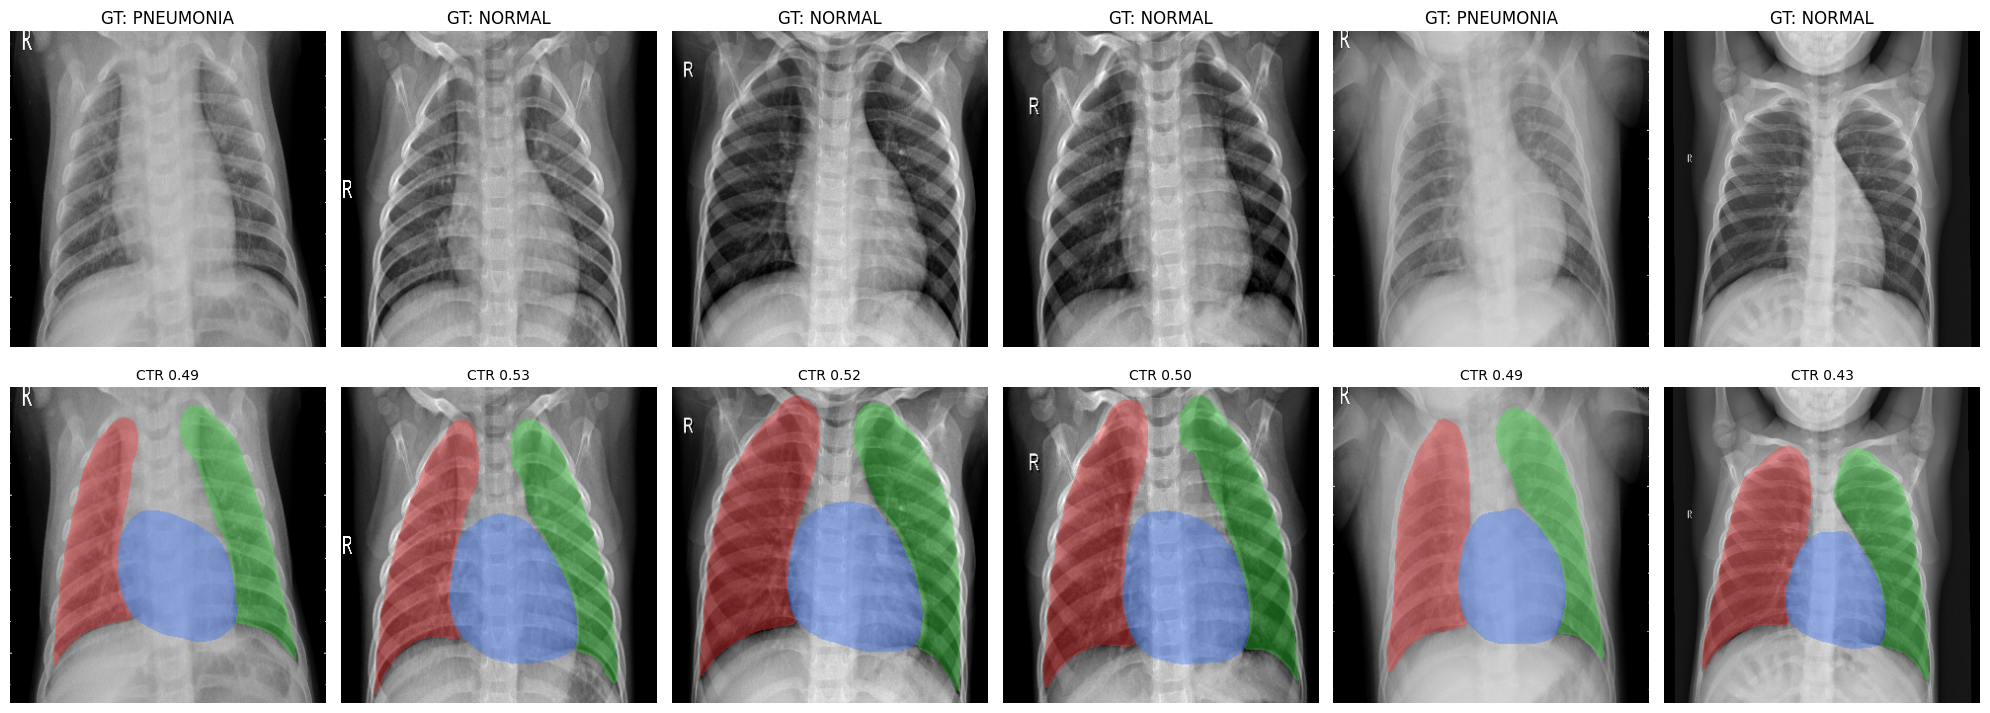

In [6]:
COLORS = {1: (255, 60, 60), 2: (60, 220, 60), 3: (60, 120, 255)}

def overlay(img, lab, alpha=0.4):
    rgb = np.stack([img] * 3, -1).astype(np.float32)
    for k, c in COLORS.items():
        rgb[lab == k] = (1 - alpha) * rgb[lab == k] + alpha * np.array(c)
    return rgb.astype(np.uint8)

def calculate_ctr(lab):
    """심흉곽비(CTR) = 심장 최대 가로폭 / 흉곽(양폐) 최대 가로폭 — 모델 카드 함수 기반"""
    lungs, heart = (lab == 1) | (lab == 2), lab == 3
    if lungs.sum() == 0 or heart.sum() == 0:
        return np.nan
    lx, hx = np.where(lungs)[1], np.where(heart)[1]
    return (hx.max() - hx.min()) / (lx.max() - lx.min())

samples = raw["test"].shuffle(seed=SEED).select(range(6))
fig, axes = plt.subplots(2, 6, figsize=(20, 7.5))
for col, ex in enumerate(samples):
    img, lab = segment(ex[IMAGE_COL])
    axes[0, col].imshow(img, cmap="gray"); axes[0, col].axis("off")
    axes[0, col].set_title(f"GT: {labels[ex[LABEL_COL]]}")
    axes[1, col].imshow(overlay(img, lab)); axes[1, col].axis("off")
    axes[1, col].set_title(f"CTR {calculate_ctr(lab):.2f}", fontsize=10)
plt.tight_layout(); plt.show()


## 5. 정답 마스크 없이 품질 점검하기 (테스트셋 624장)

이 데이터셋에는 정답 마스크가 없어 Dice/IoU를 계산할 수 없다. 대신 다음으로 **분할이 그럴듯한지** 점검한다.
- **검출률** : 양쪽 폐와 심장이 모두 검출된 비율
- **폐 면적 비율** : 이미지에서 폐가 차지하는 비율 (너무 작으면 분할 실패 의심)
- **CTR 분포** : 클래스별 비교


In [7]:
import pandas as pd
from tqdm.auto import tqdm

rows = []
t0 = time.time()
for i, ex in enumerate(tqdm(raw["test"])):
    img, lab = segment(ex[IMAGE_COL])
    rows.append({
        "idx": i, "label": labels[ex[LABEL_COL]],
        "has_R": (lab == 1).any(), "has_L": (lab == 2).any(), "has_H": (lab == 3).any(),
        "lung_area": ((lab == 1) | (lab == 2)).mean(),
        "ctr": calculate_ctr(lab),
    })
df = pd.DataFrame(rows)
print(f"추론 시간: {time.time()-t0:.1f}초 ({(time.time()-t0)/len(df)*1000:.0f} ms/장)")

df["all_found"] = df.has_R & df.has_L & df.has_H
print(f"\n양폐+심장 모두 검출: {df.all_found.mean():.3f}")
print("\n[클래스별 요약]")
print(df.groupby("label")[["lung_area", "ctr"]].agg(["mean", "std"]).round(3))



추론 시간: 58.5초 (94 ms/장)

양폐+심장 모두 검출: 1.000

[클래스별 요약]
          lung_area           ctr       
               mean    std   mean    std
label                                   
NORMAL        0.276  0.050  0.468  0.042
PNEUMONIA     0.256  0.039  0.513  0.049


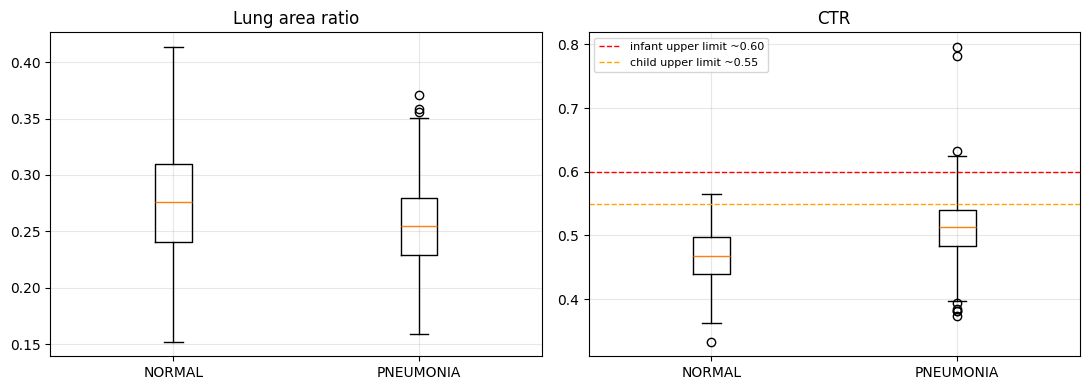

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in zip(axes, ["lung_area", "ctr"], ["Lung area ratio", "CTR"]):
    data = [df[df.label == l][col].dropna() for l in labels]
    ax.boxplot(data); ax.set_xticks(range(1, len(labels) + 1), labels); ax.set_title(title); ax.grid(alpha=0.3)
axes[1].axhline(0.60, color="red", ls="--", lw=1, label="infant upper limit ~0.60")
axes[1].axhline(0.55, color="orange", ls="--", lw=1, label="child upper limit ~0.55")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


**해석 포인트**
- **기준선 변경:** CTR 0.5는 **성인 PA** 기준이므로, 소아 기준(영아 약 0.60, 소아 약 0.55)으로 바꾸어 표시했다. 소아는 몸에 비해 심장이 상대적으로 크고, AP 촬영에서는 심장이 확대되어 보이기 때문이다.
- **CTR 결과:** NORMAL(중앙값 약 0.47)은 거의 모두 0.55 이하였다. PNEUMONIA(중앙값 약 0.51)도 대부분 0.55 이하이며, 0.60을 넘는 경우는 소수의 이상치뿐이었다. → 소아 기준으로는 **두 그룹 모두 대부분 정상 범위**이다.
- **폐 면적:** PNEUMONIA의 폐 면적 비율(약 0.25)이 NORMAL(약 0.28)보다 작았다. 폐렴 환아가 **흡기가 얕거나 누운 자세(supine)로 촬영**되었을 가능성이 있다.
- **의미:** 두 그룹의 CTR 차이는 실제 심비대(cardiomegaly)라기보다 **흡기 정도·촬영 자세 차이**를 반영할 가능성이 크다. 이는 분류 모델이 병변이 아닌 **심장 윤곽·폐 형태를 shortcut으로 사용**할 수 있음을 보여준다.
- **주의:** 이 CTR은 영상의학과 전문의의 측정값이 아니라 **AP 영상의 분할 마스크로 계산한 값**이므로, 개별 환자 진단이 아닌 **그룹 간 비교용**으로만 해석해야 한다.


## 6. 실패 사례 확인 (폐 면적이 가장 작은 4장)


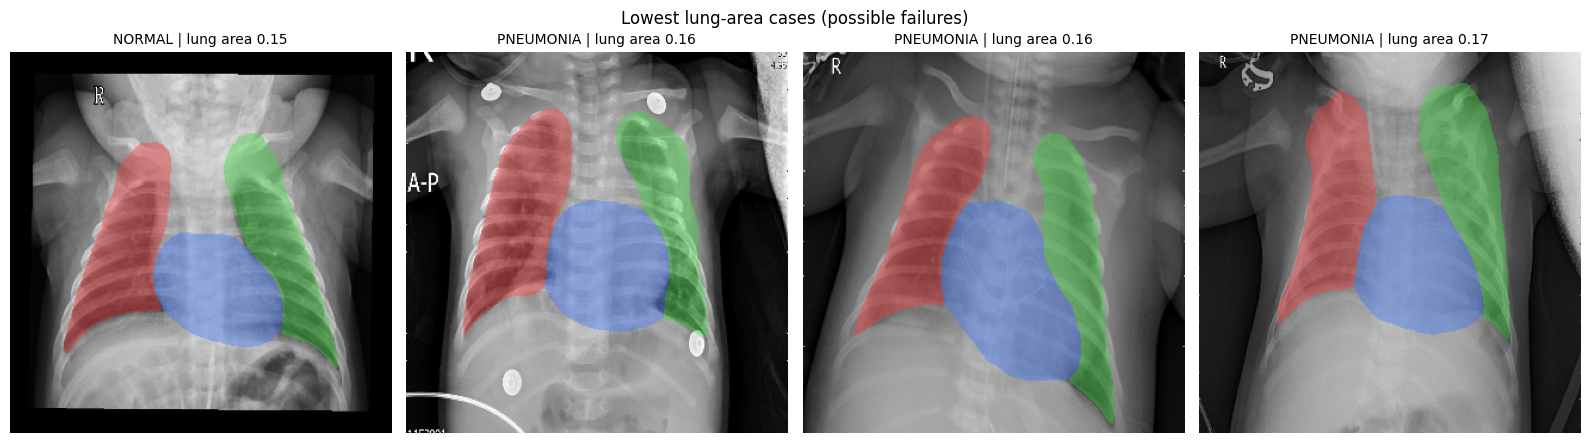

In [9]:
worst = df.sort_values("lung_area").head(4)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (_, r) in zip(axes, worst.iterrows()):
    img, lab = segment(raw["test"][int(r.idx)][IMAGE_COL])
    ax.imshow(overlay(img, lab)); ax.axis("off")
    ax.set_title(f"{r.label} | lung area {r.lung_area:.2f}", fontsize=10)
plt.suptitle("Lowest lung-area cases (possible failures)"); plt.tight_layout(); plt.show()


---
# Part 2. 분할 결과 활용 — 폐 영역만 보고 다시 분류하기

5주차 Grad-CAM의 문제(종격동·모서리를 봄)를 줄이기 위해, 분할 마스크로 **폐 영역만 남긴 이미지**를 만들어 같은 설정으로 분류 모델을 재학습한다.

- `CROP_MODE="mask"` : 폐 바깥(종격동·뼈·마커)을 검게 지우고 폐 범위로 자름 → shortcut 차단 효과가 큼
  (단, 심장 뒤 폐(retrocardiac) 병변 정보는 일부 손실)
- `CROP_MODE="bbox"` : 양폐를 감싸는 사각형만 자름 → 정보 손실은 적지만 종격동이 남음

## 7. 폐 영역 이미지 만들기 (약 5~10분)


In [10]:
KERNEL = np.ones((15, 15), np.uint8)

def lung_crop(pil_img, margin=0.05, mode=CROP_MODE):
    img, lab = segment(pil_img)
    lungs = ((lab == 1) | (lab == 2)).astype(np.uint8)
    if lungs.sum() < 100:                                   # 분할 실패 → 원본 사용
        return Image.fromarray(img).convert("RGB"), False
    if mode == "mask":
        img = img * cv2.dilate(lungs, KERNEL)               # 흉막 경계가 잘리지 않게 약간 확장
    ys, xs = np.where(lungs)
    H, W = img.shape
    my, mx = int(H * margin), int(W * margin)
    y0, y1 = max(ys.min() - my, 0), min(ys.max() + my, H)
    x0, x1 = max(xs.min() - mx, 0), min(xs.max() + mx, W)
    crop = img[y0:y1, x0:x1]
    s = max(crop.shape)                                     # 정사각형 패딩 (center crop 때 폐가 잘리지 않게)
    sq = np.zeros((s, s), np.uint8)
    oy, ox = (s - crop.shape[0]) // 2, (s - crop.shape[1]) // 2
    sq[oy:oy + crop.shape[0], ox:ox + crop.shape[1]] = crop
    return Image.fromarray(sq).convert("RGB"), True

def apply_crop(ex):
    im, ok = lung_crop(ex[IMAGE_COL])
    return {IMAGE_COL: im, "seg_ok": ok}

t0 = time.time()
crop_ds = raw.map(apply_crop)
print(f"crop 소요 시간: {(time.time()-t0)/60:.1f}분")
for s in crop_ds:
    print(f"{s:10s} 분할 실패(원본 사용): {len(crop_ds[s]) - sum(crop_ds[s]['seg_ok'])}장")


crop 소요 시간: 6.0분
train      분할 실패(원본 사용): 0장
validation 분할 실패(원본 사용): 0장
test       분할 실패(원본 사용): 0장


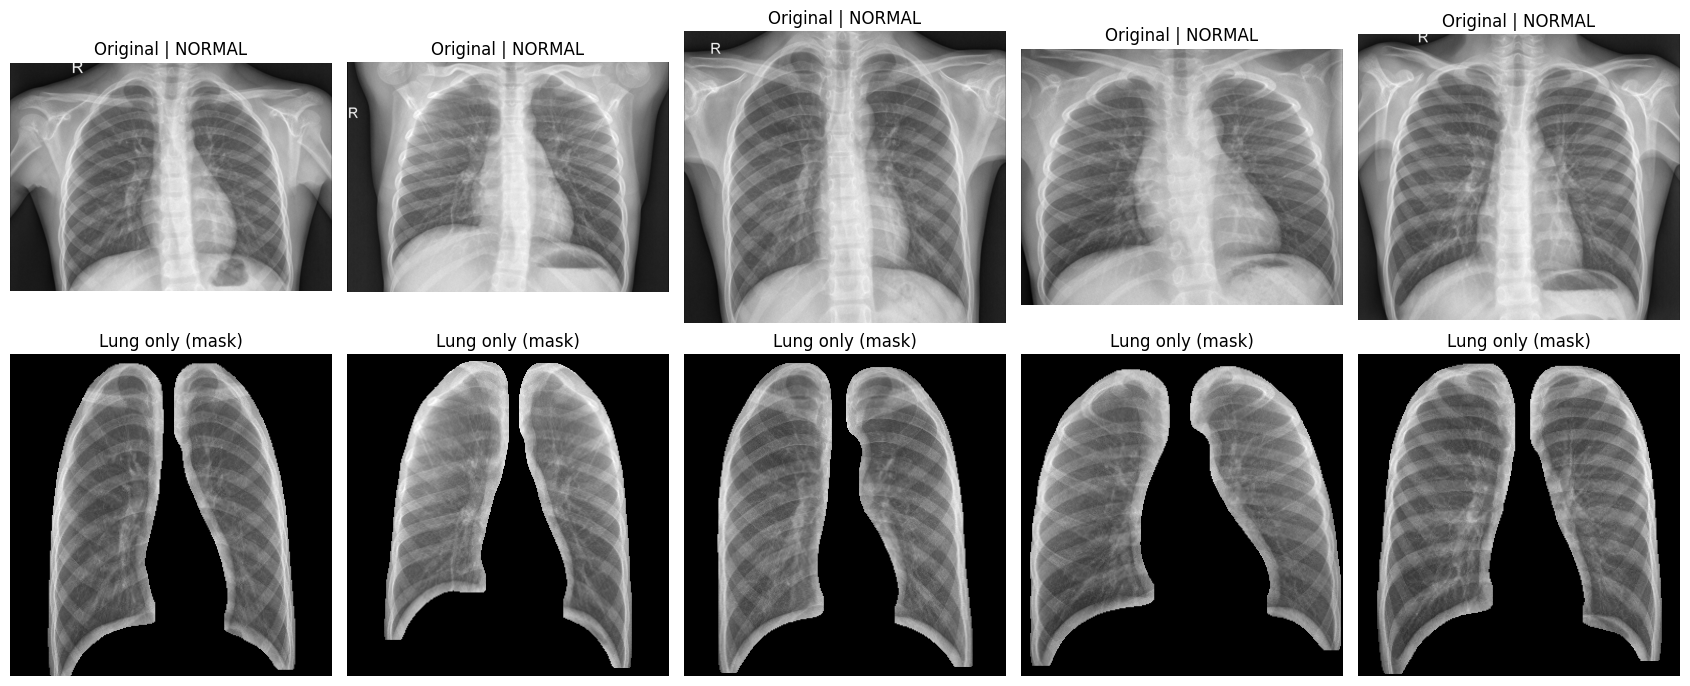

In [11]:
# 원본 vs 폐 영역 이미지 비교
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for col, i in enumerate(range(5)):
    axes[0, col].imshow(raw["test"][i][IMAGE_COL], cmap="gray"); axes[0, col].axis("off")
    axes[0, col].set_title(f"Original | {labels[raw['test'][i][LABEL_COL]]}")
    axes[1, col].imshow(crop_ds["test"][i][IMAGE_COL]); axes[1, col].axis("off")
    axes[1, col].set_title(f"Lung only ({CROP_MODE})")
plt.tight_layout(); plt.show()


## 8. 분류 모델 재학습 (5주차와 동일 설정)

5주차와 **같은 seed·같은 분할·같은 하이퍼파라미터**를 사용해, 입력 이미지만 바뀌었을 때의 차이를 비교한다.


In [12]:
from transformers import AutoImageProcessor, AutoModelForImageClassification, TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, f1_score, recall_score
from collections import Counter

split = crop_ds["train"].train_test_split(test_size=0.1, stratify_by_column=LABEL_COL, seed=SEED)
c_train, c_val, c_test = split["train"], split["test"], crop_ds["test"]
for n, d in [("train", c_train), ("val", c_val), ("test", c_test)]:
    print(f"{n:5s}: {len(d)}장 | {dict(sorted(Counter(d[LABEL_COL]).items()))}")

processor = AutoImageProcessor.from_pretrained(CLS_MODEL)
def transform(batch):
    inputs = processor([im.convert("RGB") for im in batch[IMAGE_COL]], return_tensors="pt")
    inputs["labels"] = batch[LABEL_COL]
    return inputs
train_ds, val_ds, test_ds = (d.with_transform(transform) for d in (c_train, c_val, c_test))

POS = next((i for i, n in enumerate(labels) if "pneu" in n.lower()), 1); NEG = 1 - POS
def collate_fn(batch):
    return {"pixel_values": torch.stack([x["pixel_values"] for x in batch]),
            "labels": torch.tensor([x["labels"] for x in batch])}
def compute_metrics(p):
    pr, y = np.argmax(p.predictions, 1), p.label_ids
    return {"accuracy": accuracy_score(y, pr), "f1_macro": f1_score(y, pr, average="macro"),
            "sensitivity": recall_score(y, pr, pos_label=POS, zero_division=0),
            "specificity": recall_score(y, pr, pos_label=NEG, zero_division=0)}

model = AutoModelForImageClassification.from_pretrained(
    CLS_MODEL, num_labels=len(labels),
    id2label=dict(enumerate(labels)), label2id={l: i for i, l in enumerate(labels)},
    ignore_mismatched_sizes=True)

args = TrainingArguments(
    output_dir="./convnext-lungcrop", per_device_train_batch_size=32, per_device_eval_batch_size=32,
    num_train_epochs=3, learning_rate=5e-5, eval_strategy="epoch", save_strategy="epoch",
    logging_steps=10, load_best_model_at_end=True, metric_for_best_model="f1_macro",
    save_total_limit=1, fp16=torch.cuda.is_available(), remove_unused_columns=False,
    report_to="none", seed=SEED)
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  data_collator=collate_fn, compute_metrics=compute_metrics)

t0 = time.time(); trainer.train()
print(f"학습 소요 시간: {(time.time()-t0)/60:.1f}분")


train: 4694장 | {0: 1207, 1: 3487}
val  : 522장 | {0: 134, 1: 388}
test : 624장 | {0: 234, 1: 390}


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


[transformers] ConvNextForImageClassification LOAD REPORT from: facebook/convnext-tiny-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([2])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,Sensitivity,Specificity
1,0.091561,0.158021,0.934866,0.920798,0.912371,1.000000
2,0.038538,0.061786,0.980843,0.974650,0.992268,0.947761
3,0.014851,0.050956,0.986590,0.982473,0.989691,0.977612


학습 소요 시간: 2.6분


### 학습 곡선
학습/검증 loss와 검증 정확도·F1을 epoch별로 확인해 수렴·과적합 여부를 판단한다.


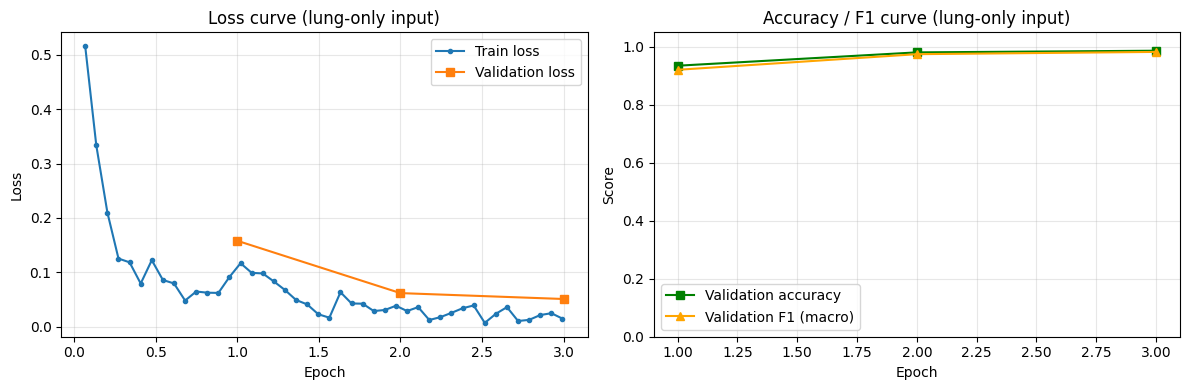

In [13]:
logs = trainer.state.log_history
train_ep, train_loss = [], []
eval_ep, eval_loss, eval_acc, eval_f1 = [], [], [], []
for rec in logs:
    if "loss" in rec and "eval_loss" not in rec and "epoch" in rec:
        train_ep.append(rec["epoch"]); train_loss.append(rec["loss"])
    if "eval_loss" in rec:
        eval_ep.append(rec["epoch"]); eval_loss.append(rec["eval_loss"])
        eval_acc.append(rec["eval_accuracy"]); eval_f1.append(rec["eval_f1_macro"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(train_ep, train_loss, marker="o", ms=3, label="Train loss")
ax1.plot(eval_ep, eval_loss, marker="s", label="Validation loss")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.set_title("Loss curve (lung-only input)")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(eval_ep, eval_acc, marker="s", color="green", label="Validation accuracy")
ax2.plot(eval_ep, eval_f1, marker="^", color="orange", label="Validation F1 (macro)")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Score"); ax2.set_title("Accuracy / F1 curve (lung-only input)")
ax2.set_ylim(0, 1.05); ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 9. 5주차(전체 이미지) vs 6주차(폐 영역) 비교

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,Sensitivity,Specificity
0.014851,0.970864,3,0.817308,0.775986,0.997436,0.517094


지표                  5주차(전체)      6주차(폐 영역)
accuracy              0.851          0.817
f1_macro              0.824          0.776
sensitivity           0.995          0.997
specificity           0.611          0.517


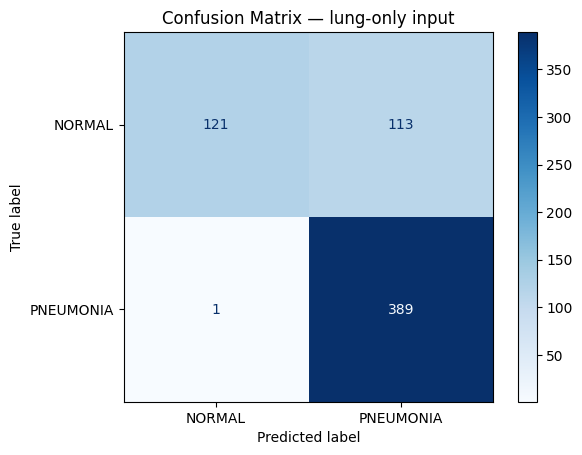

FN: 1 (5주차 2) | FP: 113 (5주차 91)


In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

after = trainer.evaluate(test_ds, metric_key_prefix="test")
print(f"{'지표':14s} {'5주차(전체)':>12s} {'6주차(폐 영역)':>14s}")
for k in ["accuracy", "f1_macro", "sensitivity", "specificity"]:
    print(f"{k:14s} {WEEK5[k]:12.3f} {after['test_'+k]:14.3f}")

pred = trainer.predict(test_ds)
cm = confusion_matrix(pred.label_ids, pred.predictions.argmax(1))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — lung-only input"); plt.show()
print(f"FN: {cm[POS, NEG]} (5주차 2) | FP: {cm[NEG, POS]} (5주차 91)")


## 10. Grad-CAM 재확인 — 이제 폐 안을 보는가?


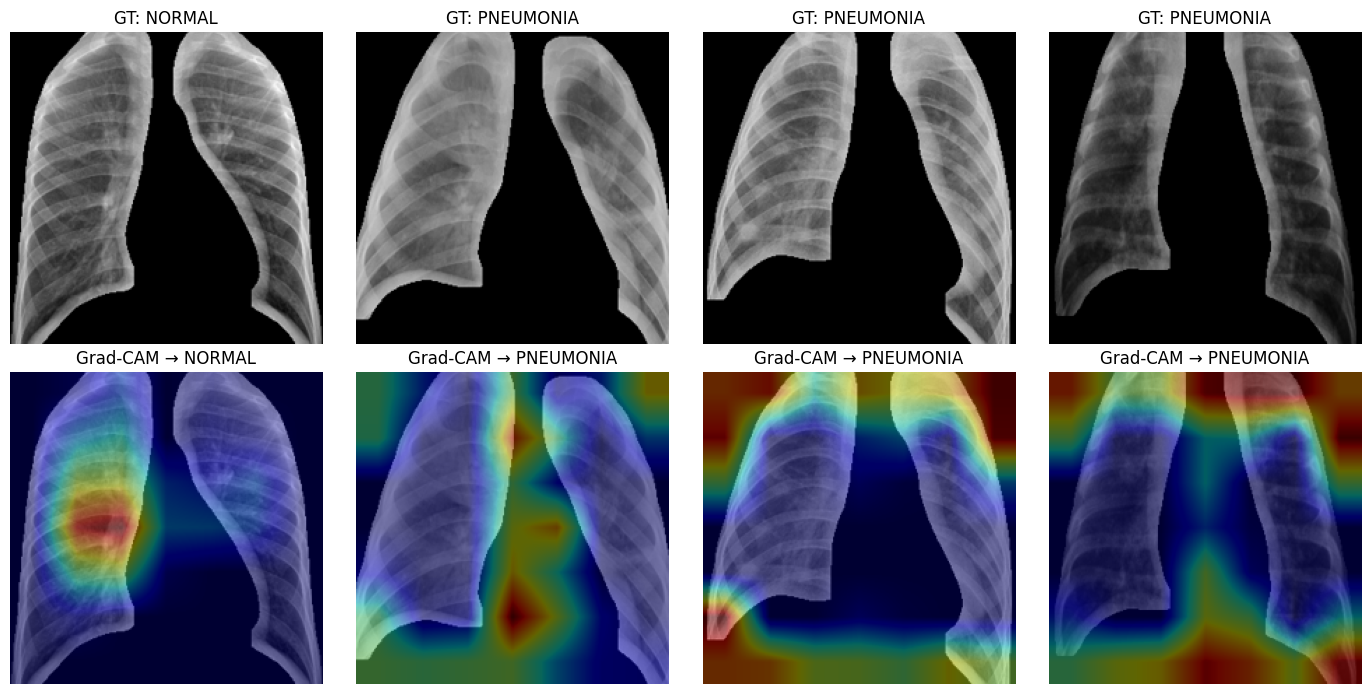

In [15]:
import torch.nn.functional as F
mean = torch.tensor(processor.image_mean).view(3, 1, 1)
std = torch.tensor(processor.image_std).view(3, 1, 1)

def gradcam(pil_img):
    m = trainer.model.eval()
    x = processor(pil_img.convert("RGB"), return_tensors="pt")["pixel_values"].to(m.device)
    out = m(pixel_values=x, output_hidden_states=True)
    feat = out.hidden_states[-1]
    cls = out.logits.argmax(-1).item()
    grad = torch.autograd.grad(out.logits[0, cls], feat)[0]
    cam = F.relu((grad.mean(dim=(2, 3), keepdim=True) * feat).sum(1, keepdim=True)).float()
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    img = (x[0].float().cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    return img, cam.detach().cpu().numpy(), m.config.id2label[cls]

idx = c_test.shuffle(seed=1).select(range(4))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for col, ex in enumerate(idx):
    img, cam, p = gradcam(ex[IMAGE_COL])
    axes[0, col].imshow(img); axes[0, col].set_title(f"GT: {labels[ex[LABEL_COL]]}"); axes[0, col].axis("off")
    axes[1, col].imshow(img); axes[1, col].imshow(cam, cmap="jet", alpha=0.4)
    axes[1, col].set_title(f"Grad-CAM → {p}"); axes[1, col].axis("off")
plt.tight_layout(); plt.show()


**Grad-CAM 비교 포인트**
- 5주차: 종격동·척추·이미지 모서리에 집중
- 6주차: 히트맵이 **폐야 내부, 특히 음영 증가 부위(consolidation)** 로 이동했는가?
- 성능이 조금 떨어지더라도 근거가 해부학적으로 타당해졌다면, **임상 신뢰성 측면에서는 개선**으로 볼 수 있다.

---
## 정리

| 단계 | 내용 |
|---|---|
| ① 분할 | `AutoModel.from_pretrained(SEG_MODEL, trust_remote_code=True)` → 우폐·좌폐·심장 마스크 |
| ② 점검 | 검출률, 폐 면적, CTR로 분할 품질 확인 |
| ③ 활용 | 폐 영역 crop → 분류 재학습 → 5주차와 성능·Grad-CAM 비교 |
